<a href="https://colab.research.google.com/github/aurioldegbelo/sis2026/blob/main/2026_VisualQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The notebook covers

* Part 1: Image Generation (Gemini)
* Part 2: Image Question Answering (Gemini)
* Part 3: Video Question Answering (Gemini)
* Part 4: Retrieval of Image and Video from APIS (Examples: Kartaview and Youtube Data API)
* Part 5: Image Search (powered by the OpenAI Clip model for embedding computation)

#Part 1: Image Generation

Code adapted from the [LangChain](https://docs.langchain.com/oss/python/integrations/chat/google_generative_ai) documentation

In [ ]:
!pip install -qU langchain-google-genai

In [11]:
# You can get a GOOGLE/Gemini API key from https://ai.google.dev/gemini-api/docs/api-key
import getpass
import os

if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass.getpass("Enter your Google AI API key: ")

Enter your Google AI API key: ··········


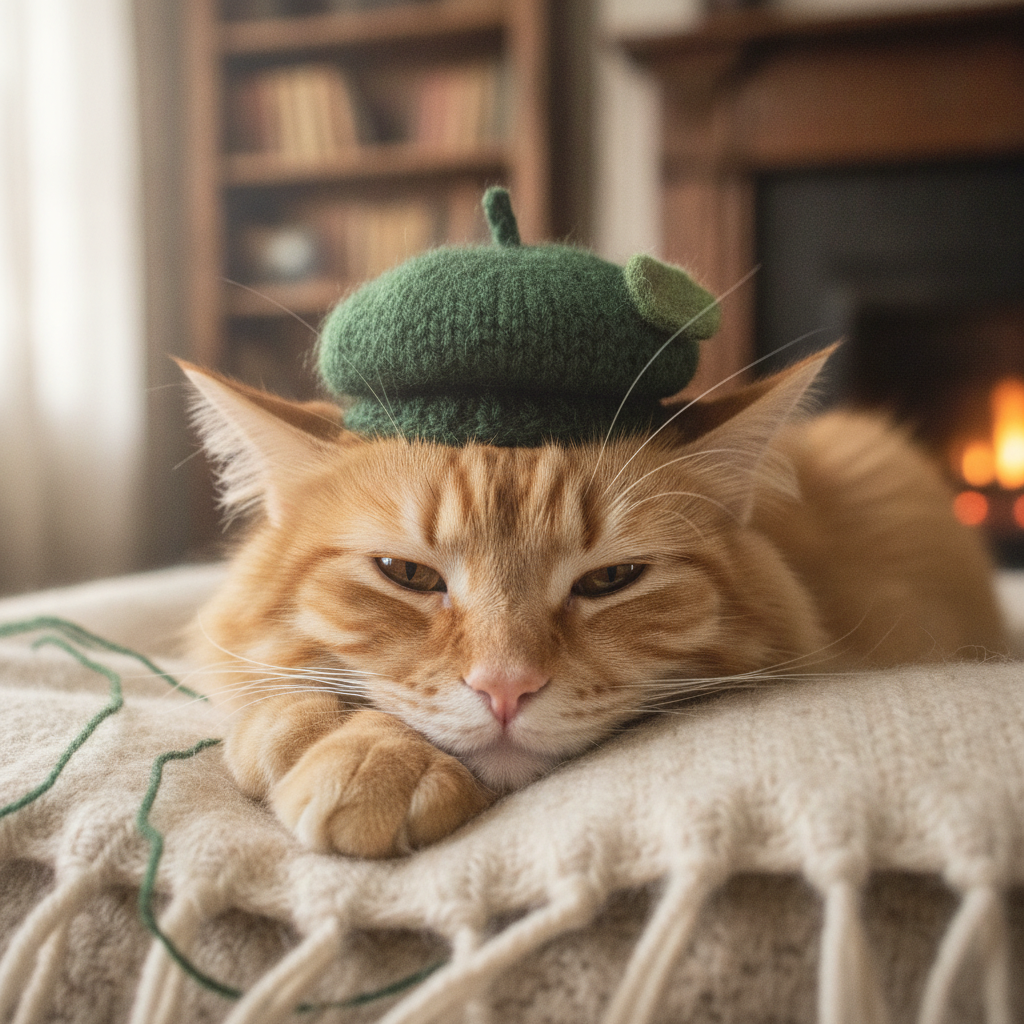

In [18]:
import base64
from IPython.display import Image, display
from langchain.messages import AIMessage
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-2.5-flash-image")

response = model.invoke("Generate a photorealistic image of a cuddly cat wearing a hat.")

def _get_image_base64(response: AIMessage) -> None:
    image_block = next(
        block
        for block in response.content
        if isinstance(block, dict) and block.get("image_url")
    )
    return image_block["image_url"].get("url").split(",")[-1]

image_base64 = _get_image_base64(response)
display(Image(data=base64.b64decode(image_base64), width=500))

# Part 2: Image Question Answering

Describe the content of an image

In [ ]:
!pip install -qU langchain-google-genai

In [27]:
from langchain.messages import HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.7-flash")

message = HumanMessage(
    content=[
        {"type": "text", "text": "Describe the image at the URL."},
        {
            "type": "image",
            "url": "https://picsum.photos/seed/picsum/200/300",
        },
    ]
)
response = model.invoke([message])
response.content

[{'type': 'text',
  'text': 'A serene, minimalist winter alpine landscape captured during sunrise or sunset:\n\n* **Foreground:** Smooth, gently undulating hills of pristine snow in deep blue, cool-toned shadows dominate the lower third of the frame.\n* **Right Side:** A steep, rugged mountain peak dusted with snow rises sharply into the frame, with subtle wisps of blowing snow or low clouds catching the light around its summit.\n* **Sky:** The upper two-thirds features an expansive sky filled with soft, layered clouds illuminated in warm pastel shades of peach, pink, and pale lavender, contrasting with the cool blue tones of the snow-covered ground below. \n\nThe overall composition evokes a tranquil, cold, and majestic atmosphere typical of high-altitude mountain environments at dusk or dawn.',
  'extras': {'signature': 'EtsJCtgJAWkUfRNGqy37e14cYHQheAy60WokGkN8IQHNImedqouXrsDHGwmz5OiFkrULLeemWUVi7pacpli4NSF0e8XDKCbDvJ9SCrd8trNrMwkQRFTtjBwP6ziR1XIhkd6SSohVOMlcJR8ekK3zUvBOHap6hAaQX2bOd

Show an image and answer questions about its content

In [36]:
# Custom code to download an image from a url

import os
import requests

def download_image(url: str) -> str:
    """Downloads an image from the specified URL."""

    # Send a get request to the url
    response = requests.get(url)

    if response.status_code != 200:
        raise Exception(f"Failed to download image from {url}")

    # Define image related variables
    image_path = os.path.basename(url)
    image_bytes = response.content
    image_type = response.headers["Content-Type"]

    print("Image type: ", image_type)
    # Check for image type, currently only PNG or JPEG format are supported
    if image_type not in {"image/png", "image/jpeg"}:
        raise ValueError("Image can only be in PNG or JPEG format")

    # Write image data to a file
    with open(image_path, "wb") as f:
        f.write(image_bytes)
    return image_path

Image type:  image/png


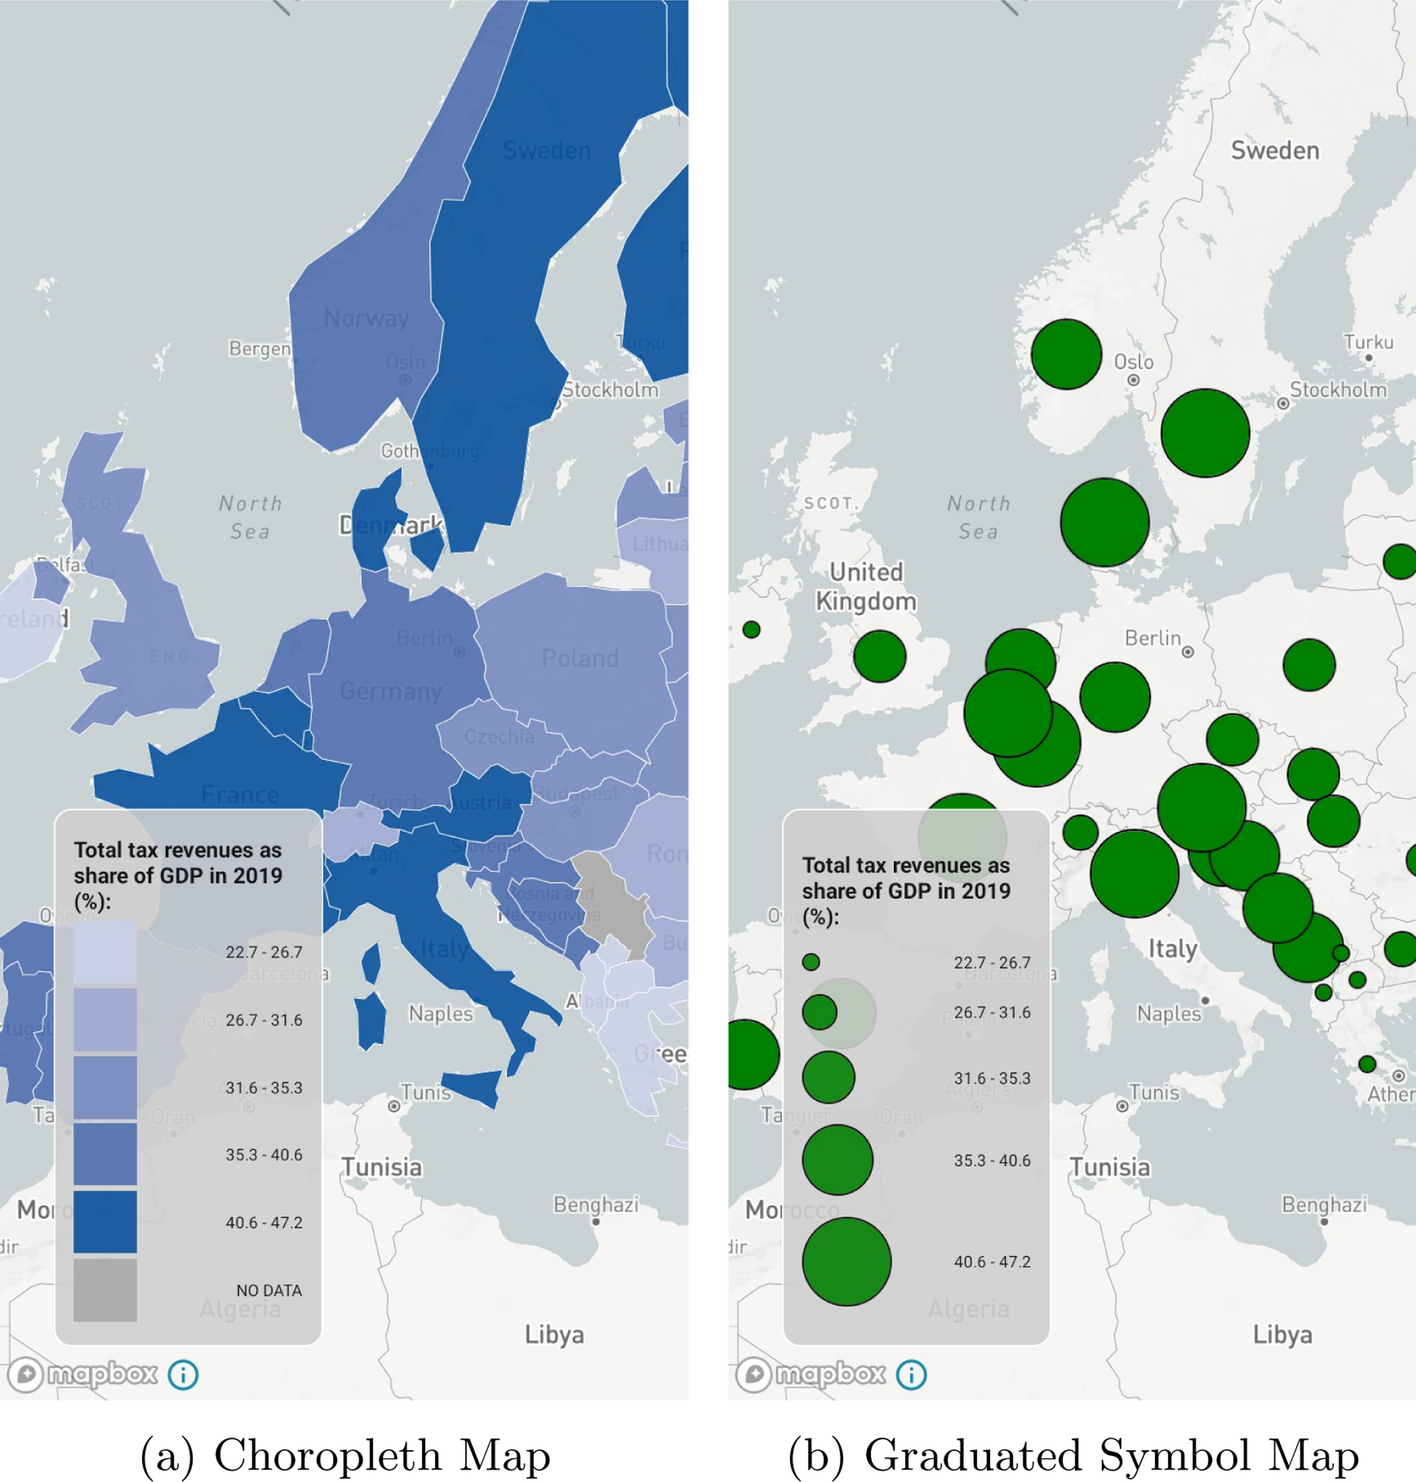

In [41]:
from PIL import Image

url = "https://media.springernature.com/full/springer-static/image/art%3A10.1007%2Fs42489-023-00136-8/MediaObjects/42489_2023_136_Fig1_HTML.png"
image_path = download_image(url)
image = Image.open(image_path)
image

Image type:  image/png


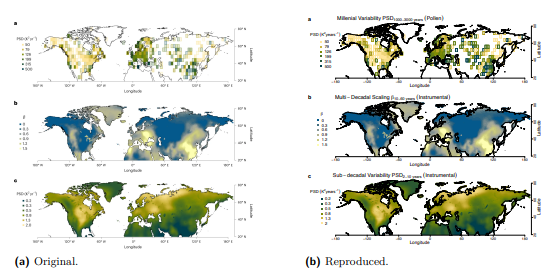

'There are **6** maps shown in the image (3 under "(a) Original" on the left, and 3 under "(b) Reproduced" on the right).'

In [45]:
from langchain.messages import HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from IPython.display import display


question1= "What is shown in the image?"

question2 = "How many maps are shown in the image?"

question3 = "What are the colour of the maps shown in the image?"

question4= "Are there any map in the image?"

question5 = "Are there any map legend in the image?"

question6 = "What is the size of the image?"

question7 = "What is the resolution of the image?"

question8 = "What is the format of the image?"

question9 = "Which countries are shown in the image?"


url = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic2.png"

image_path = download_image(url)
image = Image.open(image_path)
display(image)

question = question2

model = ChatGoogleGenerativeAI(model="gemini-3.7-flash")

message = HumanMessage(
    content=[
        {"type": "text", "text": question},
        {
            "type": "image",
            "url": url,
        },
    ]
)
response = model.invoke([message])
response.content[0]['text']

# Part 3: Video Question Answering

In [22]:
from langchain.chat_models import init_chat_model

model = init_chat_model("google_genai:gemini-3.7-flash")

message = {
    "role": "user",
    "content": [
        {
            "type": "video",
            "url": "https://youtu.be/JyUDzxMBY6A?si=fvb-htS4foohDl2t",
            "mime_type": "video/mp4",
        },
        {"type": "text", "text": "What is the sensebox according to the video? Give the answer in one sentence and the minute where you found it"},
    ],
}
response = model.invoke([message])
print(response.content)

[{'type': 'text', 'text': 'According to the video (at **00:24–00:40**), the **senseBox** is a do-it-yourself minicomputer connected to various sensors that functions like a small weather or environmental monitoring station. \n\n*(Alternatively, at **03:25**, it is summarized as a toolkit for citizen science and digital education).*', 'extras': {'signature': 'EscMCsQMAWkUfROrrUUTmfed9cCaPzqecolbLMev/SSJJMc+GxGV4lX0Td8we79qu/tYcrAA9Htgx/DM5G4b2+SM8jSPT6z7DgbMAp/eDAECD28HafLabx1PXli8g8yuuda7oEwXCBDKw/UMHUti2XrUSKNzlhYdeQzXW4AylopOlUY9Dt/+5atEKXtis+g2tCRQyUydZAhVP71ojgsRzSLiyAkq40SgX/4tcuHRlaXmJP+srXgB9GYjQonhIU0miBVc7gK7lLbf8GOGNGdP9A6MzrtDCmV0TkT3gXSrtYeoGRG0TSLGC8rS2UXCakiA5cmGyv0Q8a7a59hI3+/VuzQlmoz4CYLMvIye5f5lSTbNvB91dUMTysZ4kFhE3VWd4FNe7Bm7RAAvSUgcFVeieLRKYmTIzWdzZ6A9+mHwLu3Yw76EPdWHT+uk+JuLjzMislCD5UGlePauKWTIa1/xnE6wDmFbNLLVBmyyU6zuhGLwqTzjd4+Q6Xx/LIh5WXpD3ElG7Xv6GCIholVIvPoMAF8CFr6YY2CUxCxMf/UmURzI394VnIddtEMwCAKMocrT8HxmzGUusTBBYyOv/VF+wBJA4b0BJ7HKkIhY+3b5+S9my04HAXHUwO3YG560zWd

# Part 4: Image and Video Retrieval from APIS

## [KartaView](https://kartaview.org/doc/authentication)

In [46]:
import requests

url = "https://api.openstreetcam.org/2.0/photo/"
params = {
    "lat": 51.9625,
    "lng": 7.62556,
    "zoomLevel": 15
}

try:
    response = requests.get(url, params=params)
    response.raise_for_status()  # Check for HTTP errors
    data = response.json()
    import pprint
    pprint.pprint(data)
except requests.exceptions.RequestException as e:
    print(f"An error occurred: {e}")

{'result': {'data': [{'additionalInformation': None,
                      'autoImgProcessingResult': 'BLURRED',
                      'autoImgProcessingStatus': 'FINISHED',
                      'cameraParameters': None,
                      'dateAdded': '2022-09-29 04:18:08',
                      'dateProcessed': '2022-09-29 04:18:09',
                      'distance': None,
                      'fieldOfView': None,
                      'filepath': '2022/9/29/{{sizeprefix}}/6163593_db3a1_63351c7fa16b0.jpg',
                      'filepathLTh': '2022/9/29/lth/6163593_db3a1_63351c7fa16b0.jpg',
                      'filepathProc': '2022/9/29/proc/6163593_db3a1_63351c7fa16b0.jpg',
                      'filepathTh': '2022/9/29/th/6163593_db3a1_63351c7fa16b0.jpg',
                      'fileurl': 'https://storage13.openstreetcam.org/files/photo/2022/9/29/{{sizeprefix}}/6163593_db3a1_63351c7fa16b0.jpg',
                      'fileurlLTh': 'https://storage13.openstreetcam.org/files/pho

## Youtube Data API

In [47]:
!pip install -q google-api-python-client

In [48]:
YOUTUBE_API_KEY = "yourKey" # get one from the google cloud console

In [49]:
import os
from googleapiclient.discovery import build

def get_videos_by_location(api_key, latitude, longitude, radius="10km", max_results=10):
    """
    Retrieves a list of videos matching a specific location and radius.
    """
    # Initialize the YouTube API client
    youtube = build('youtube', 'v3', developerKey=api_key)

    # Define the coordinates format: 'lat,long'
    location_coords = f"{latitude},{longitude}"

    # Execute the search request
    # 'type="video"' is required when searching with location parameters
    request = youtube.search().list(
        part="snippet",
        type="video",
        location=location_coords,
        locationRadius=radius,
        maxResults=max_results,
        q=""  # You can add a keyword string here to filter further (e.g., "vlog")
    )

    response = request.execute()

    # Parse and display the results
    print(f"--- Videos found within {radius} of ({location_coords}) ---")
    for item in response.get("items", []):
        video_title = item["snippet"]["title"]
        video_id = item["id"]["videoId"]
        channel_title = item["snippet"]["channelTitle"]
        video_url = f"https://www.youtube.com/watch?v={video_id}"

        print(f"\nTitle: {video_title}")
        print(f"Channel: {channel_title}")
        print(f"URL: {video_url}")

if __name__ == "__main__":
    # 1. Setup your API Key
    # Replace 'YOUR_API_KEY' with the key generated from your Google Cloud Console
    API_KEY = YOUTUBE_API_KEY

    # 2. Define coordinates (Example: Paris, France)
    LATITUDE = 48.8566
    LONGITUDE = 2.3522
    RADIUS = "20km"  # Supported units: m, km, ft, mi

    get_videos_by_location(
        api_key=API_KEY,
        latitude=LATITUDE,
        longitude=LONGITUDE,
        radius=RADIUS,
        max_results=5
    )


--- Videos found within 20km of (48.8566,2.3522) ---

Title: Guess what dessert I made inspired by the flea market in Paris?!#paris #fleamarket #dessert #recipe
Channel: Ainsley Durose
URL: https://www.youtube.com/watch?v=E3kzOhKOrSA

Title: 🎾 #MajaChwalinska had a hilarious interaction with #JohnMcEnroe at #rolandgarros  on the TNT Desk🎾
Channel: RADIO SPORT POLONIA 1
URL: https://www.youtube.com/watch?v=dciqHKTNdwA

Title: Let’s make a pistachio &amp; raspberry cake in my tiny Parisian kitchen! #paris #pastry #recipe #cake
Channel: Ainsley Durose
URL: https://www.youtube.com/watch?v=y4wFeuP5ut0

Title: Alléluia ✔️🙏❤️ #louange #adoration #jesus #viral #movie #tiktok #youtubeshorts #love #fyp #dance
Channel: LEE MWANA YESU
URL: https://www.youtube.com/watch?v=rkPUM3DNyTQ

Title: Let’s make Ratatuille in my tiny Parisian kitchen#paris #cooking #disney #kitchen #recipe #baking
Channel: Ainsley Durose
URL: https://www.youtube.com/watch?v=8X6R95bDE8Y


# Part 5: CLIP for embedding computation and Image Search

In [50]:
!pip install -q torch torchvision pillow

!pip install -q git+https://github.com/openai/CLIP.git

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.8 MB/s eta 0:00:00


In [51]:
# code adapted from https://llmapi.ai/how-to-find-similar-images-using-python/

import torch
import clip
from PIL import Image

import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

model, preprocess = clip.load("ViT-B/32", device=device)

# compute image embeddings based on the clip model
def get_image_embedding(image_path):

    image = preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)

    with torch.no_grad():

        embedding = model.encode_image(image)

    embedding = embedding / embedding.norm(dim=-1, keepdim=True)

    return embedding.cpu().numpy()[0]

100%|███████████████████████████████████████| 338M/338M [00:03<00:00, 98.7MiB/s]


In [52]:
clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [53]:
# Custom function to download and visualize an image
import os
import requests

def download_image(url: str) -> str:
    """Downloads an image from the specified URL."""

    # Send a get request to the url
    response = requests.get(url)

    if response.status_code != 200:
        raise Exception(f"Failed to download image from {url}")

    # Define image related variables
    image_path = os.path.basename(url)
    image_bytes = response.content
    image_type = response.headers["Content-Type"]

    print("Image type: ", image_type)
    # Check for image type, currently only PNG or JPEG format are supported
    if image_type not in {"image/png", "image/jpeg"}:
        raise ValueError("Image can only be in PNG or JPEG format")

    # Write image data to a file
    with open(image_path, "wb") as f:
        f.write(image_bytes)
    return image_path

Image type:  image/jpeg


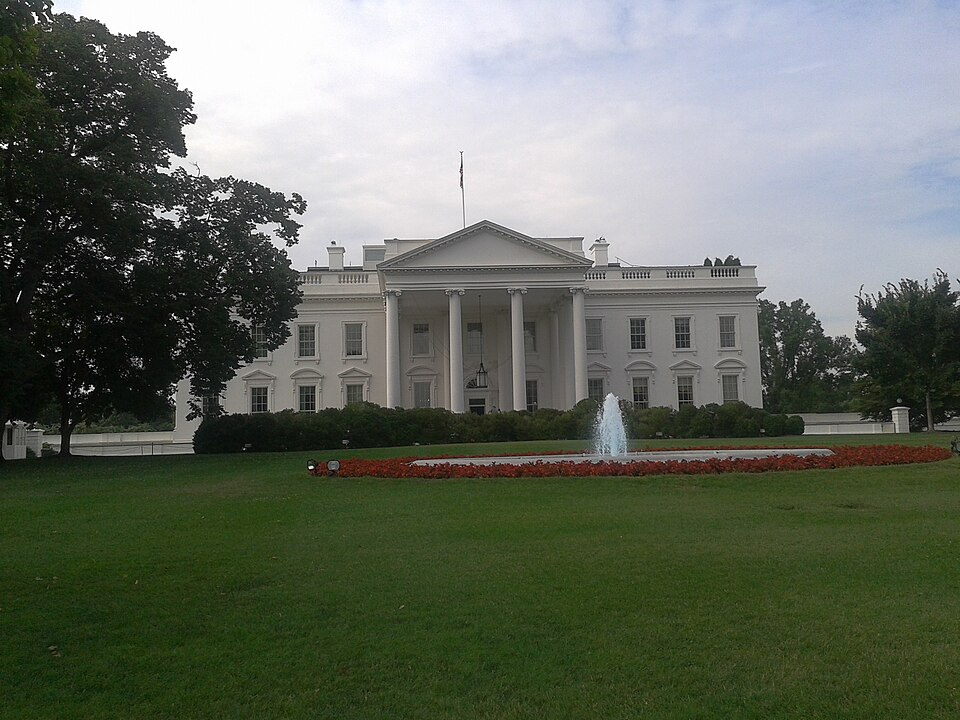

In [54]:
from PIL import Image

# selected examples of images
url1 = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic1.jpg"
url2 = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic2.png"
url3 = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic3.jpg"
url4 = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic4.jpg"
url5 = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic5.jpg"

image_path = download_image(url5)

image = Image.open(image_path)
image

In [55]:
# compute all embeddings for all images and save them in a dictionary (this way we can do a lookup afterwards)
all_images = [url1, url2, url3, url4, url5]

embedding_dictionary = []

for url in all_images:
    image_path = download_image(url)
    embedding = get_image_embedding(image_path)
    item = {
        "url": url,
        "embedding": embedding
    }
    embedding_dictionary.append(item)

Image type:  image/jpeg
Image type:  image/png
Image type:  image/jpeg
Image type:  image/jpeg
Image type:  image/jpeg


In [56]:
embeddings = [item['embedding'] for item in embedding_dictionary]
print(f"Extracted {len(embeddings)} embeddings.")

Extracted 5 embeddings.


In [57]:
from sklearn.metrics.pairwise import cosine_similarity
import re

def find_similar_images(url, image_embeddings, top_n=3):

  # Extracting the digits from the filename
  match = re.search(r'pic(\d+)\.', url)

  if match:
    number = match.group(1)
    print(f"Extracted picture number: {number}")

    # compute the similarity scores (pairwise similarity computation between the embeddings)
    similarity_scores = cosine_similarity(image_embeddings, image_embeddings)

    # get the similarity scores for the  current picture
    score_current_picture = similarity_scores[int(number)-1]
    print(score_current_picture)
    # Get indices sorted in descending order of value
    sorted_indices = np.argsort(score_current_picture)[::-1]

    print("Indices of items from highest to lowest score:")
    for rank, idx in enumerate(sorted_indices, 1):
        print(f"Rank {rank}: Index {idx}, Name {embedding_dictionary[idx]['url']} (Score: {score_current_picture[idx]:.8f})")
        if rank == top_n:
            break

  else:
      print("No picture found for the given url.")


selected_image = "https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic3.jpg"

find_similar_images(selected_image, embeddings, top_n=3)

Extracted picture number: 3
[0.39943242 0.37681    1.         0.77849436 0.54436386]
Indices of items from highest to lowest score:
Rank 1: Index 2, Name https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic3.jpg (Score: 1.00000000)
Rank 2: Index 3, Name https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic4.jpg (Score: 0.77849436)
Rank 3: Index 4, Name https://raw.githubusercontent.com/aurioldegbelo/sis2026/main/raster_data/pic5.jpg (Score: 0.54436386)


# Additional Links

Reading/recent papers on Visual Question Answering: https://huggingface.co/papers/trending?q=Visual+question+answering

Hugging Face Intro to Visual Question Answering:
https://huggingface.co/tasks/visual-question-answering
